# 02 · Stage 1: switching points and the $\sqrt{\lambda}$ law

**Purpose.** Fits the Stage 1 switching points with the square-root law and with a fixed-delay law, frees the exponent, and compares the switch-off coefficient with the parameter-free prediction. It answers: does the lag behind a moving threshold grow as $\sqrt{\lambda}$, with the predicted coefficient?

**In the report.** Chapter 4, Sec. 4.2: Eqs. (4.1)–(4.3), Fig. 4.2, the exponents and the effective noise floor $\Lambda_{\rm on}$.

## Theory

For a ramp $R_F(t) = R_c + \lambda t$ through the threshold $R_c$, with $G_R = 1/R_i$ (notebook 00):

$$R_{\rm on} = R_c + k_{\rm on}\sqrt{\lambda}, \qquad R_{\rm off} = R_c - k_{\rm off}\sqrt{\lambda}, \qquad k_{\rm off} = 2\sqrt{\frac{\ln 10\,R_i}{\omega_0}}. \tag{4.1–4.3}$$

A fixed response time $t_d$ would instead give a shift linear in the rate, $R_c \pm \lambda t_d$ (Eq. 2.28). The fitted $k_{\rm on}$ gives the effective growth needed to switch on, $\Lambda_{\rm on} = k_{\rm on}^2\,\omega_0/(4R_i)$, and so an effective starting amplitude $\delta = 0.9A_{\rm sat}e^{-\Lambda_{\rm on}}$.

## Method

1. Read the summary table (one row per simulated rate: `Lambda`, `R_threshold_reached`; positive rates are ramps up, negative ramps down).
2. Least-squares fits (`scipy.optimize.curve_fit`) of three models to each direction: $R_c \pm k\sqrt{\lambda}$; $R_c \pm t_d\lambda$; and $R_c \pm k\lambda^a$ with a free exponent $a$.
3. Compare the models by their rms residual and by the Akaike information criterion, $\mathrm{AIC} = n\ln(\mathrm{RSS}/n) + 2p$ ($p$ = number of parameters). A lower AIC is better.
4. Compare the fitted $k_{\rm off}$ with the parameter-free value.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
SUMMARY_CSV = "../data/stage1/simulation_summary_master.csv"   # columns: Lambda (ohm/s, sign = direction), R_threshold_reached (ohm)
OMEGA0      = 500.0      # 1/s, natural frequency 1/RC of the simulated circuit (R = 1 k, C = 2 uF)
R_I         = 47e3       # ohm, input resistor (G_R = 1/R_I for an R_F sweep)
R_C_IDEAL   = 94e3       # ohm, ideal threshold 2 R_i, for plots only
A_SAT       = 13.9       # V, full amplitude, for the effective noise floor
OUT_DIR     = "outputs/02_stage1_fits"

## 1. Load the switching points

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
os.makedirs(OUT_DIR, exist_ok=True)
m = pd.read_csv(SUMMARY_CSV)
up = m[m.Lambda > 0].sort_values("Lambda"); dn = m[m.Lambda < 0].assign(lam=lambda d: -d.Lambda).sort_values("lam")
x_on, y_on = up.Lambda.to_numpy(float), up.R_threshold_reached.to_numpy(float)
x_off, y_off = dn.lam.to_numpy(float), dn.R_threshold_reached.to_numpy(float)
print(f"{len(up)} ramps up ({x_on.min():g}-{x_on.max():g} ohm/s), {len(dn)} ramps down ({x_off.min():g}-{x_off.max():g} ohm/s)")

36 ramps up (10-10000 ohm/s), 28 ramps down (40-10000 ohm/s)


## 2. Fit the three laws

In [3]:
def aic(res, p):
    n = len(res); return n * np.log((res**2).sum() / n) + 2 * p

def fit_all(x, y, sign):
    models = {"sqrt":  (lambda l, R, k: R + sign * k * np.sqrt(l), [94000, 40]),
              "fixed delay": (lambda l, R, t: R + sign * t * l, [94000, 0.3]),
              "free exponent": (lambda l, R, k, a: R + sign * k * l**a, [94000, 40, 0.5])}
    out = {}
    for name, (f, p0) in models.items():
        p, c = curve_fit(f, x, y, p0=p0, maxfev=20000); r = y - f(x, *p)
        out[name] = dict(f=f, p=p, err=np.sqrt(np.diag(c)), rms=r.std(), AIC=aic(r, len(p)))
    return out

fits = {"switch-on (ramp up)": fit_all(x_on, y_on, +1), "switch-off (ramp down)": fit_all(x_off, y_off, -1)}
for name, fs in fits.items():
    s, d, e = fs["sqrt"], fs["fixed delay"], fs["free exponent"]
    print(f"{name}:")
    print(f"   sqrt law:     R_c = {s['p'][0]:.1f} +/- {s['err'][0]:.1f} ohm,  k = {s['p'][1]:.2f} +/- {s['err'][1]:.2f},  rms {s['rms']:.1f} ohm, AIC {s['AIC']:.1f}")
    print(f"   fixed delay:  rms {d['rms']:.1f} ohm, AIC {d['AIC']:.1f}")
    print(f"   free exponent a = {e['p'][2]:.3f} +/- {e['err'][2]:.3f}")

switch-on (ramp up):
   sqrt law:     R_c = 93924.4 +/- 13.1 ohm,  k = 51.97 +/- 0.29,  rms 49.0 ohm, AIC 284.1
   fixed delay:  rms 335.4 ohm, AIC 422.7
   free exponent a = 0.546 +/- 0.005
switch-off (ramp down):
   sqrt law:     R_c = 94001.3 +/- 2.5 ohm,  k = 29.62 +/- 0.05,  rms 7.2 ohm, AIC 114.6
   fixed delay:  rms 195.3 ohm, AIC 299.4
   free exponent a = 0.499 +/- 0.003


## 3. Compare with the parameter-free prediction

In [4]:
k_off_theory = 2 * np.sqrt(np.log(10) * R_I / OMEGA0)
k_on, k_off = fits["switch-on (ramp up)"]["sqrt"]["p"][1], fits["switch-off (ramp down)"]["sqrt"]["p"][1]
L_on = k_on**2 * OMEGA0 / (4 * R_I)
print(f"k_off fitted {k_off:.2f}, theory {k_off_theory:.2f}  ({100*(k_off/k_off_theory-1):+.1f} %)")
print(f"Lambda_on = {L_on:.2f} -> effective starting amplitude {0.9*A_SAT*np.exp(-L_on)*1e3:.1f} mV;  k_on/k_off = {k_on/k_off:.2f}")

k_off fitted 29.62, theory 29.42  (+0.7 %)
Lambda_on = 7.18 -> effective starting amplitude 9.5 mV;  k_on/k_off = 1.75


## 4. Figure (as Fig. 4.2)

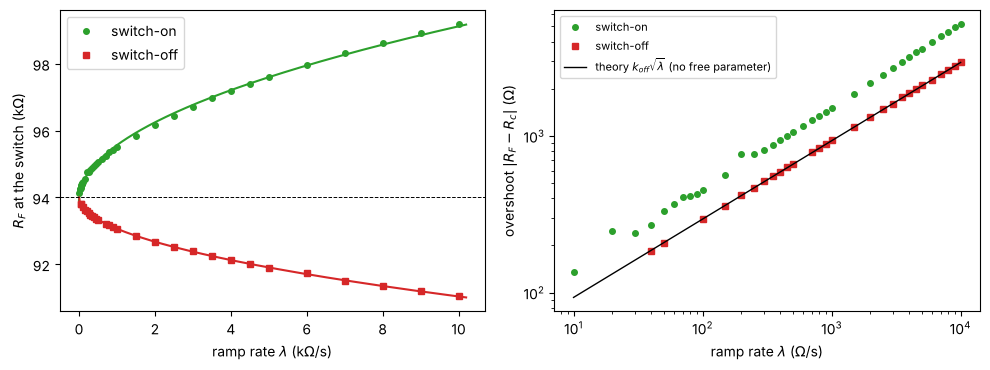

In [5]:
L = np.linspace(0, x_on.max() * 1.02, 400)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axs[0]
ax.plot(x_on / 1e3, y_on / 1e3, "o", ms=4, color="tab:green", label="switch-on")
ax.plot(x_off / 1e3, y_off / 1e3, "s", ms=4, color="tab:red", label="switch-off")
ax.plot(L / 1e3, fits["switch-on (ramp up)"]["sqrt"]["f"](L, *fits["switch-on (ramp up)"]["sqrt"]["p"]) / 1e3, color="tab:green")
ax.plot(L / 1e3, fits["switch-off (ramp down)"]["sqrt"]["f"](L, *fits["switch-off (ramp down)"]["sqrt"]["p"]) / 1e3, color="tab:red")
ax.axhline(R_C_IDEAL / 1e3, color="k", ls="--", lw=0.7)
ax.set_xlabel(r"ramp rate $\lambda$ (k$\Omega$/s)"); ax.set_ylabel(r"$R_F$ at the switch (k$\Omega$)"); ax.legend()
ax = axs[1]
ax.loglog(x_on, y_on - R_C_IDEAL, "o", ms=4, color="tab:green", label="switch-on")
ax.loglog(x_off, R_C_IDEAL - y_off, "s", ms=4, color="tab:red", label="switch-off")
Lg = np.logspace(1, 4, 50)
ax.loglog(Lg, k_off_theory * np.sqrt(Lg), "k", lw=1, label=r"theory $k_{off}\sqrt{\lambda}$ (no free parameter)")
ax.set_xlabel(r"ramp rate $\lambda$ ($\Omega$/s)"); ax.set_ylabel(r"overshoot $|R_F - R_c|$ ($\Omega$)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "stage1_fits.png"), dpi=150); plt.show()

## Check against the report

In [6]:
s_on, s_off = fits["switch-on (ramp up)"]["sqrt"], fits["switch-off (ramp down)"]["sqrt"]
checks = {
    "Eq. 4.1: R_on = 93924 + 51.97 sqrt(lambda)": abs(s_on["p"][0] - 93924) < 1 and abs(s_on["p"][1] - 51.97) < 0.01,
    "Eq. 4.2: R_off = 94001.3 - 29.62 sqrt(lambda)": abs(s_off["p"][0] - 94001.3) < 0.1 and abs(s_off["p"][1] - 29.62) < 0.01,
    "Eq. 4.3: k_off theory = 29.4": abs(k_off_theory - 29.4) < 0.05,
    "exponents 0.499 (off) and 0.546 (on)": abs(fits["switch-off (ramp down)"]["free exponent"]["p"][2] - 0.499) < 0.001
        and abs(fits["switch-on (ramp up)"]["free exponent"]["p"][2] - 0.546) < 0.001,
    "Lambda_on = 7.2": abs(L_on - 7.2) < 0.05,
}
for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)

PASS Eq. 4.1: R_on = 93924 + 51.97 sqrt(lambda)
PASS Eq. 4.2: R_off = 94001.3 - 29.62 sqrt(lambda)
PASS Eq. 4.3: k_off theory = 29.4
PASS exponents 0.499 (off) and 0.546 (on)
PASS Lambda_on = 7.2


## Using your own data

Provide a CSV with a column `Lambda` (ramp rate in Ω/s, positive for switch-on runs, negative for switch-off runs) and a column `R_threshold_reached` (resistance at the switch, Ω), and set `OMEGA0` and `R_I` for your circuit. The fits assume a linear relation between gain and swept resistance near threshold, which holds exactly for an $R_F$ sweep.